# Phase 07 — Revenue Impact & Business Recommendations

## Revenue Baseline and Opportunity Modeling

This notebook evaluates historical purchase-event value,
customer and segment revenue patterns, and hypothetical
conversion improvement scenarios.

### Analytical Principles

- Use the existing cleaned October customer sample.
- Preserve the validated journey-level funnel definitions.
- Distinguish purchase events from unique orders.
- Treat recorded purchase-event value as a revenue proxy.
- Do not assume a currency without verification.
- Clearly distinguish historical observations from hypothetical improvements.
- Avoid double-counting customers, events, and journeys.
- Do not interpret gross revenue uplift as profit or ROI.

In [1]:

# Step 07.07 — Load Cleaned Dataset for Revenue Analysis

# 1. Import required libraries
from pathlib import Path
import pandas as pd
import numpy as np

# 2. Locate the cleaned dataset
data_path = Path("data/clean/october_customer_sample_clean.csv")

# Support notebooks launched from the notebooks/ folder
if not data_path.exists():
    data_path = Path("../data/clean/october_customer_sample_clean.csv")

# 3. Verify that the dataset exists
assert data_path.exists(), f"Dataset not found: {data_path}"

# 4. Load the cleaned October sample
df = pd.read_csv(data_path)

# 5. Display basic information
print("=== PHASE 07 — DATASET LOADED ===")
print(f"Total event records: {len(df):,}")
print(f"Total columns: {len(df.columns)}")
print(f"Purchase events: {(df['event_type'] == 'purchase').sum():,}")
print("\nColumn names:")
print(df.columns.tolist())


=== PHASE 07 — DATASET LOADED ===
Total event records: 849,220
Total columns: 9
Purchase events: 15,435

Column names:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']


In [2]:

# Step 07.08 — Historical Purchase-Event Value Baseline

# 1. Filter purchase events only
purchase_df = df.loc[df["event_type"] == "purchase"].copy()

# 2. Validate purchase prices
missing_prices = purchase_df["price"].isna().sum()
invalid_prices = (purchase_df["price"] <= 0).sum()

assert missing_prices == 0, "Missing purchase prices detected"
assert invalid_prices == 0, "Invalid purchase prices detected"

# 3. Calculate purchase-event value
# Use decimal arithmetic to preserve financial precision
from decimal import Decimal

purchase_values = purchase_df["price"].map(
    lambda value: Decimal(str(value))
)

purchase_event_count = len(purchase_df)
total_purchase_value = sum(purchase_values, Decimal("0"))

average_purchase_value = (
    total_purchase_value / purchase_event_count
    if purchase_event_count > 0
    else Decimal("0")
)

# 4. Display historical baseline
print("=== PHASE 07 — REVENUE BASELINE ===")
print(f"Purchase events: {purchase_event_count:,}")
print(f"Total purchase-event value: {total_purchase_value:,.2f}")
print(f"Average purchase-event value: {average_purchase_value:,.2f}")
print(f"Missing purchase prices: {missing_prices}")
print(f"Invalid purchase prices: {invalid_prices}")
print("Currency: Unverified")


=== PHASE 07 — REVENUE BASELINE ===
Purchase events: 15,435
Total purchase-event value: 4,979,242.62
Average purchase-event value: 322.59
Missing purchase prices: 0
Invalid purchase prices: 0
Currency: Unverified


In [3]:

# Step 07.09 — Purchase-Event Value Distribution

# 1. Calculate descriptive statistics
price_stats = purchase_df["price"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

# 2. Display the distribution
print("=== PURCHASE-EVENT VALUE DISTRIBUTION ===")
print(f"Minimum: {price_stats['min']:,.2f}")
print(f"25th percentile: {price_stats['25%']:,.2f}")
print(f"Median (50th): {price_stats['50%']:,.2f}")
print(f"75th percentile: {price_stats['75%']:,.2f}")
print(f"90th percentile: {price_stats['90%']:,.2f}")
print(f"95th percentile: {price_stats['95%']:,.2f}")
print(f"99th percentile: {price_stats['99%']:,.2f}")
print(f"Maximum: {price_stats['max']:,.2f}")

# 3. Compare average and median
print("\n=== AVERAGE VS MEDIAN ===")
print(f"Average purchase-event value: {average_purchase_value:,.2f}")
print(f"Median purchase-event value: {price_stats['50%']:,.2f}")


=== PURCHASE-EVENT VALUE DISTRIBUTION ===
Minimum: 0.92
25th percentile: 90.07
Median (50th): 187.89
75th percentile: 391.00
90th percentile: 900.64
95th percentile: 1,090.89
99th percentile: 1,622.18
Maximum: 2,557.59

=== AVERAGE VS MEDIAN ===
Average purchase-event value: 322.59
Median purchase-event value: 187.89


In [4]:

# Step 07.10 — Purchase-Event Value Concentration

# 1. Sort purchase events by price (highest first)
sorted_purchases = purchase_df.sort_values(
    by="price",
    ascending=False
).reset_index(drop=True)

# 2. Calculate concentration for top event groups
total_events = len(sorted_purchases)
total_value = sorted_purchases["price"].sum()

print("=== PURCHASE-EVENT VALUE CONCENTRATION ===")

for top_pct in [1, 5, 10, 20]:
    # Number of events in the top percentage
    top_n = max(1, int(np.ceil(total_events * top_pct / 100)))

    # Sum of values for those events
    top_value = sorted_purchases["price"].iloc[:top_n].sum()

    # Share of total recorded purchase-event value
    value_share = (
        top_value / total_value * 100
        if total_value > 0
        else 0
    )

    print(
        f"Top {top_pct}% of purchase events "
        f"({top_n:,} events): "
        f"{value_share:.2f}% of total value"
    )


=== PURCHASE-EVENT VALUE CONCENTRATION ===
Top 1% of purchase events (155 events): 5.48% of total value
Top 5% of purchase events (772 events): 21.70% of total value
Top 10% of purchase events (1,544 events): 37.20% of total value
Top 20% of purchase events (3,087 events): 57.81% of total value


In [5]:

# Step 07.11 — Customer-Level Purchase Value Analysis

# 1. Aggregate purchase events by customer
customer_purchase_value = (
    purchase_df.groupby("user_id")
    .agg(
        purchase_events=("event_type", "size"),
        total_purchase_value=("price", "sum")
    )
    .reset_index()
)

# 2. Calculate customer-level metrics
purchasing_customers = len(customer_purchase_value)

avg_value_per_purchasing_customer = (
    customer_purchase_value["total_purchase_value"].mean()
)

median_value_per_purchasing_customer = (
    customer_purchase_value["total_purchase_value"].median()
)

# 3. Validate reconciliation with historical baseline
customer_value_total = (
    customer_purchase_value["total_purchase_value"].sum()
)

assert np.isclose(
    customer_value_total,
    float(total_purchase_value),
    rtol=0,
    atol=0.01
), "Customer purchase values do not match baseline"

# 4. Display results
print("=== CUSTOMER-LEVEL PURCHASE VALUE ===")
print(f"Purchasing customers: {purchasing_customers:,}")
print(
    f"Average value per purchasing customer: "
    f"{avg_value_per_purchasing_customer:,.2f}"
)
print(
    f"Median value per purchasing customer: "
    f"{median_value_per_purchasing_customer:,.2f}"
)
print(
    f"Reconciled total purchase-event value: "
    f"{customer_value_total:,.2f}"
)


=== CUSTOMER-LEVEL PURCHASE VALUE ===
Purchasing customers: 7,099
Average value per purchasing customer: 701.40
Median value per purchasing customer: 232.69
Reconciled total purchase-event value: 4,979,242.62


In [6]:

# Step 07.12 — Customer Purchase-Value Concentration

# 1. Sort purchasing customers by total recorded value
sorted_customers = customer_purchase_value.sort_values(
    by="total_purchase_value",
    ascending=False
).reset_index(drop=True)

# 2. Calculate the customer population and total value
total_customers = len(sorted_customers)

customer_total_value = (
    sorted_customers["total_purchase_value"].sum()
)

# 3. Verify consistency with the historical baseline
assert np.isclose(
    customer_total_value,
    float(total_purchase_value),
    rtol=0,
    atol=0.01
), "Customer totals do not reconcile"

# 4. Calculate concentration by customer group
print("=== CUSTOMER PURCHASE-VALUE CONCENTRATION ===")

for top_pct in [1, 5, 10, 20]:
    top_n = max(
        1,
        int(np.ceil(total_customers * top_pct / 100))
    )

    top_value = (
        sorted_customers["total_purchase_value"]
        .iloc[:top_n]
        .sum()
    )

    value_share = (
        top_value / customer_total_value * 100
        if customer_total_value > 0
        else 0
    )

    print(
        f"Top {top_pct}% of purchasing customers "
        f"({top_n:,} customers): "
        f"{value_share:.2f}% of total purchase value"
    )


=== CUSTOMER PURCHASE-VALUE CONCENTRATION ===
Top 1% of purchasing customers (71 customers): 25.98% of total purchase value
Top 5% of purchasing customers (355 customers): 47.55% of total purchase value
Top 10% of purchasing customers (710 customers): 60.20% of total purchase value
Top 20% of purchasing customers (1,420 customers): 74.51% of total purchase value


In [7]:

# Step 07.13 — Purchase Value per Customer

# 1. Count all unique customers in the cleaned sample
total_unique_customers = df["user_id"].nunique()

# 2. Calculate purchase-event value per sampled customer
value_per_customer = (
    total_purchase_value / total_unique_customers
    if total_unique_customers > 0
    else Decimal("0")
)

# 3. Calculate customer purchase participation
purchase_participation_rate = (
    purchasing_customers / total_unique_customers * 100
    if total_unique_customers > 0
    else 0
)

# 4. Display customer-level financial metrics
print("=== CUSTOMER-LEVEL FINANCIAL BASELINE ===")
print(f"Total unique customers: {total_unique_customers:,}")
print(f"Purchasing customers: {purchasing_customers:,}")
print(
    f"Customer purchase participation: "
    f"{purchase_participation_rate:.2f}%"
)
print(
    f"Purchase-event value per sampled customer: "
    f"{value_per_customer:,.2f}"
)
print("Currency: Unverified")


=== CUSTOMER-LEVEL FINANCIAL BASELINE ===
Total unique customers: 60,939
Purchasing customers: 7,099
Customer purchase participation: 11.65%
Purchase-event value per sampled customer: 81.71
Currency: Unverified


In [8]:

# Step 07.14 — Purchase Value by Product Category

# 1. Standardize missing category labels for reporting
category_purchases = purchase_df.copy()

category_purchases["category_code"] = (
    category_purchases["category_code"]
    .fillna("Unknown")
    .replace("", "Unknown")
)

# 2. Aggregate purchase events by category
category_value = (
    category_purchases.groupby("category_code")
    .agg(
        purchase_events=("event_type", "size"),
        purchase_value=("price", "sum")
    )
    .reset_index()
    .sort_values("purchase_value", ascending=False)
)

# 3. Calculate each category's share of purchase value
category_value["value_share_pct"] = (
    category_value["purchase_value"]
    / category_value["purchase_value"].sum()
    * 100
)

# 4. Validate the aggregated total
assert np.isclose(
    category_value["purchase_value"].sum(),
    float(total_purchase_value),
    rtol=0,
    atol=0.01
), "Category purchase values do not reconcile"

# 5. Display the top 10 categories
print("=== TOP 10 CATEGORIES BY PURCHASE VALUE ===")

print(
    category_value[
        [
            "category_code",
            "purchase_events",
            "purchase_value",
            "value_share_pct"
        ]
    ]
    .head(10)
    .to_string(
        index=False,
        formatters={
            "purchase_value": "{:,.2f}".format,
            "value_share_pct": "{:.2f}%".format
        }
    )
)


=== TOP 10 CATEGORIES BY PURCHASE VALUE ===
                   category_code  purchase_events purchase_value value_share_pct
          electronics.smartphone             7068   3,486,772.03          70.03%
                         Unknown             3527     460,562.28           9.25%
              computers.notebook              344     174,168.29           3.50%
            electronics.video.tv              398     151,536.95           3.04%
       appliances.kitchen.washer              377     114,462.98           2.30%
              electronics.clocks              366      98,623.35           1.98%
appliances.kitchen.refrigerators              255      88,378.83           1.77%
     electronics.audio.headphone              696      87,311.18           1.75%
   appliances.environment.vacuum              250      34,678.95           0.70%
              electronics.tablet              112      28,256.68           0.57%


In [9]:

# Step 07.15 — Purchase Value by Brand

# 1. Prepare brand labels
brand_purchases = purchase_df.copy()

brand_purchases["brand"] = (
    brand_purchases["brand"]
    .fillna("Unknown")
    .replace("", "Unknown")
)

# 2. Aggregate purchase events by brand
brand_value = (
    brand_purchases.groupby("brand")
    .agg(
        purchase_events=("event_type", "size"),
        purchase_value=("price", "sum")
    )
    .reset_index()
    .sort_values("purchase_value", ascending=False)
)

# 3. Calculate each brand's value share
brand_value["value_share_pct"] = (
    brand_value["purchase_value"]
    / brand_value["purchase_value"].sum()
    * 100
)

# 4. Reconcile brand totals with historical baseline
assert np.isclose(
    brand_value["purchase_value"].sum(),
    float(total_purchase_value),
    rtol=0,
    atol=0.01
), "Brand purchase values do not reconcile"

# 5. Display top 10 brands
print("=== TOP 10 BRANDS BY PURCHASE VALUE ===")

print(
    brand_value[
        [
            "brand",
            "purchase_events",
            "purchase_value",
            "value_share_pct"
        ]
    ]
    .head(10)
    .to_string(
        index=False,
        formatters={
            "purchase_value": "{:,.2f}".format,
            "value_share_pct": "{:.2f}%".format
        }
    )
)


=== TOP 10 BRANDS BY PURCHASE VALUE ===
  brand  purchase_events purchase_value value_share_pct
  apple             3076   2,373,666.81          47.67%
samsung             3594   1,105,806.56          22.21%
Unknown             1318     211,968.36           4.26%
 xiaomi             1190     201,531.90           4.05%
 huawei              449      91,906.24           1.85%
   acer              168      83,085.88           1.67%
     lg              179      66,035.49           1.33%
lucente              230      62,108.87           1.25%
   oppo              243      53,839.98           1.08%
   sony              119      36,293.39           0.73%


In [10]:

# Step 07.16 — Customer Activity and Purchase Value

# 1. Count recorded events for each customer
customer_activity = (
    df.groupby("user_id")
    .size()
    .reset_index(name="event_count")
)

# 2. Inspect the distribution before applying segment rules
print("=== CUSTOMER ACTIVITY DISTRIBUTION ===")

print(
    customer_activity["event_count"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

# 3. Check existing Phase 05 segmentation variables
print("\n=== EXISTING SEGMENTATION VARIABLES ===")

segment_variables = [
    name for name in globals()
    if "segment" in name.lower()
]

print(segment_variables)

print(
    "\nNext: Reuse the validated Phase 05 "
    "activity-segment definitions."
)


=== CUSTOMER ACTIVITY DISTRIBUTION ===
count    60939.000000
mean        13.935575
std         31.416577
min          1.000000
25%          2.000000
50%          4.000000
75%         13.000000
90%         33.000000
95%         56.000000
max       1062.000000
Name: event_count, dtype: float64

=== EXISTING SEGMENTATION VARIABLES ===
[]

Next: Reuse the validated Phase 05 activity-segment definitions.


In [11]:

# Step 07.18 — Purchase Value by Customer Activity Segment

# 1. Reuse the original Phase 05 activity thresholds
activity_labels = [
    "Low Activity",
    "Medium Activity",
    "High Activity",
    "Very High Activity"
]

customer_activity["activity_segment"] = pd.cut(
    customer_activity["event_count"],
    bins=[0, 4, 13, 56, float("inf")],
    labels=activity_labels
)

# 2. Attach customer purchase values
activity_value = customer_activity.merge(
    customer_purchase_value[
        ["user_id", "purchase_events", "total_purchase_value"]
    ],
    on="user_id",
    how="left",
    validate="one_to_one"
)

# 3. Customers without purchase events contribute zero
activity_value["purchase_events"] = (
    activity_value["purchase_events"].fillna(0)
)

activity_value["total_purchase_value"] = (
    activity_value["total_purchase_value"].fillna(0)
)

# 4. Summarize activity segments
activity_value_summary = (
    activity_value.groupby("activity_segment", observed=True)
    .agg(
        customers=("user_id", "nunique"),
        purchasing_customers=(
            "purchase_events",
            lambda x: (x > 0).sum()
        ),
        purchase_value=("total_purchase_value", "sum")
    )
    .reset_index()
)

# 5. Calculate value shares
activity_value_summary["value_share_pct"] = (
    activity_value_summary["purchase_value"]
    / activity_value_summary["purchase_value"].sum()
    * 100
)

# 6. Validate totals
assert activity_value_summary["customers"].sum() == 60939

assert (
    activity_value_summary["purchasing_customers"].sum()
    == 7099
)

assert np.isclose(
    activity_value_summary["purchase_value"].sum(),
    float(total_purchase_value),
    rtol=0,
    atol=0.01
)

# 7. Display results
print("=== PURCHASE VALUE BY ACTIVITY SEGMENT ===")

print(
    activity_value_summary.to_string(
        index=False,
        formatters={
            "purchase_value": "{:,.2f}".format,
            "value_share_pct": "{:.2f}%".format
        }
    )
)


=== PURCHASE VALUE BY ACTIVITY SEGMENT ===
  activity_segment  customers  purchasing_customers purchase_value value_share_pct
      Low Activity      30626                   657     197,338.99           3.96%
   Medium Activity      15371                  1932     775,752.29          15.58%
     High Activity      11902                  3032   1,819,038.72          36.53%
Very High Activity       3040                  1478   2,187,112.62          43.92%


In [12]:

# Step 07.19 — Purchase Participation by Activity Segment

# 1. Calculate purchase participation
activity_value_summary["purchase_participation_pct"] = (
    activity_value_summary["purchasing_customers"]
    / activity_value_summary["customers"]
    * 100
)

# 2. Calculate value per customer within each segment
activity_value_summary["value_per_customer"] = (
    activity_value_summary["purchase_value"]
    / activity_value_summary["customers"]
)

# 3. Calculate average value per purchasing customer
activity_value_summary["value_per_purchaser"] = (
    activity_value_summary["purchase_value"]
    / activity_value_summary["purchasing_customers"]
)

# 4. Display results
print("=== ACTIVITY SEGMENT PURCHASE PARTICIPATION ===")

print(
    activity_value_summary[
        [
            "activity_segment",
            "customers",
            "purchasing_customers",
            "purchase_participation_pct",
            "value_per_customer",
            "value_per_purchaser"
        ]
    ].to_string(
        index=False,
        formatters={
            "purchase_participation_pct": "{:.2f}%".format,
            "value_per_customer": "{:,.2f}".format,
            "value_per_purchaser": "{:,.2f}".format
        }
    )
)


=== ACTIVITY SEGMENT PURCHASE PARTICIPATION ===
  activity_segment  customers  purchasing_customers purchase_participation_pct value_per_customer value_per_purchaser
      Low Activity      30626                   657                      2.15%               6.44              300.36
   Medium Activity      15371                  1932                     12.57%              50.47              401.53
     High Activity      11902                  3032                     25.47%             152.83              599.95
Very High Activity       3040                  1478                     48.62%             719.44            1,479.78


In [13]:

# Step 07.20 — Validate Activity Segment Financial Metrics

from decimal import Decimal

# 1. Reconcile customer counts
segment_customers = int(
    activity_value_summary["customers"].sum()
)

segment_purchasers = int(
    activity_value_summary["purchasing_customers"].sum()
)

assert segment_customers == 60939
assert segment_purchasers == 7099

# 2. Reconcile purchase-event value
segment_value = sum(
    Decimal(str(value))
    for value in activity_value_summary["purchase_value"]
)

assert abs(
    segment_value - total_purchase_value
) < Decimal("0.01")

# 3. Validate participation rates
assert activity_value_summary[
    "purchase_participation_pct"
].between(0, 100).all()

# 4. Display results
print("=== ACTIVITY SEGMENT FINANCIAL VALIDATION ===")
print(f"Customers: {segment_customers:,}")
print(f"Purchasing customers: {segment_purchasers:,}")
print(f"Purchase-event value: {segment_value:,.2f}")
print("Participation rates: VALID")
print("All activity segment financial checks: PASSED")


=== ACTIVITY SEGMENT FINANCIAL VALIDATION ===
Customers: 60,939
Purchasing customers: 7,099
Purchase-event value: 4,979,242.62
Participation rates: VALID
All activity segment financial checks: PASSED


In [14]:

# Step 07.21 — Purchase-Value Opportunity Scenarios

# 1. Historical customer baseline
total_customers = 60939
purchasing_customers = 7099

baseline_participation = (
    purchasing_customers / total_customers
)

# 2. Historical value per purchasing customer
baseline_value_per_purchaser = (
    float(total_purchase_value) / purchasing_customers
)

# 3. Hypothetical relative participation improvements
improvement_scenarios = [0.05, 0.10, 0.15, 0.20]

scenario_results = []

for improvement in improvement_scenarios:

    scenario_participation = min(
        baseline_participation * (1 + improvement),
        1.0
    )

    additional_purchasers = (
        total_customers
        * (scenario_participation - baseline_participation)
    )

    incremental_value = (
        additional_purchasers
        * baseline_value_per_purchaser
    )

    scenario_results.append({
        "relative_improvement": f"{improvement:.0%}",
        "projected_participation_pct": round(
            scenario_participation * 100, 2
        ),
        "additional_purchasers": round(additional_purchasers),
        "incremental_purchase_value": round(
            incremental_value, 2
        )
    })

scenario_df = pd.DataFrame(scenario_results)

print("=== HYPOTHETICAL PURCHASE PARTICIPATION SCENARIOS ===")
print(scenario_df.to_string(index=False))

print("\nThese are modeled scenarios, not observed results.")
print("Currency remains unverified.")
print("Incremental purchase value is not profit or ROI.")


=== HYPOTHETICAL PURCHASE PARTICIPATION SCENARIOS ===
relative_improvement  projected_participation_pct  additional_purchasers  incremental_purchase_value
                  5%                        12.23                    355                   248962.13
                 10%                        12.81                    710                   497924.26
                 15%                        13.40                   1065                   746886.39
                 20%                        13.98                   1420                   995848.52

These are modeled scenarios, not observed results.
Currency remains unverified.
Incremental purchase value is not profit or ROI.


In [15]:

# Step 07.22 — Validate Opportunity Scenarios

from decimal import Decimal

# 1. Verify historical baseline
assert total_customers == 60939
assert purchasing_customers == 7099

assert abs(
    float(total_purchase_value) - 4979242.62
) < 0.01

# 2. Verify scenario improvement levels
expected_improvements = ["5%", "10%", "15%", "20%"]

assert (
    scenario_df["relative_improvement"].tolist()
    == expected_improvements
)

# 3. Recalculate each scenario independently
for improvement, row in zip(
    improvement_scenarios,
    scenario_df.to_dict("records")
):
    expected_rate = min(
        baseline_participation * (1 + improvement),
        1.0
    )

    expected_additional = (
        total_customers
        * (expected_rate - baseline_participation)
    )

    expected_value = (
        expected_additional
        * baseline_value_per_purchaser
    )

    assert abs(
        row["projected_participation_pct"]
        - round(expected_rate * 100, 2)
    ) < 0.01

    assert row["additional_purchasers"] == round(
        expected_additional
    )

    assert abs(
        row["incremental_purchase_value"]
        - round(expected_value, 2)
    ) < 0.01

# 4. Verify scenario ordering
assert scenario_df[
    "incremental_purchase_value"
].is_monotonic_increasing

print("=== OPPORTUNITY SCENARIO VALIDATION ===")
print("Historical baseline: PASSED")
print("Improvement levels: PASSED")
print("Participation calculations: PASSED")
print("Additional purchaser calculations: PASSED")
print("Incremental value calculations: PASSED")
print("Scenario ordering: PASSED")
print("\nALL OPPORTUNITY SCENARIO CHECKS PASSED")


=== OPPORTUNITY SCENARIO VALIDATION ===
Historical baseline: PASSED
Improvement levels: PASSED
Participation calculations: PASSED
Additional purchaser calculations: PASSED
Incremental value calculations: PASSED
Scenario ordering: PASSED

ALL OPPORTUNITY SCENARIO CHECKS PASSED


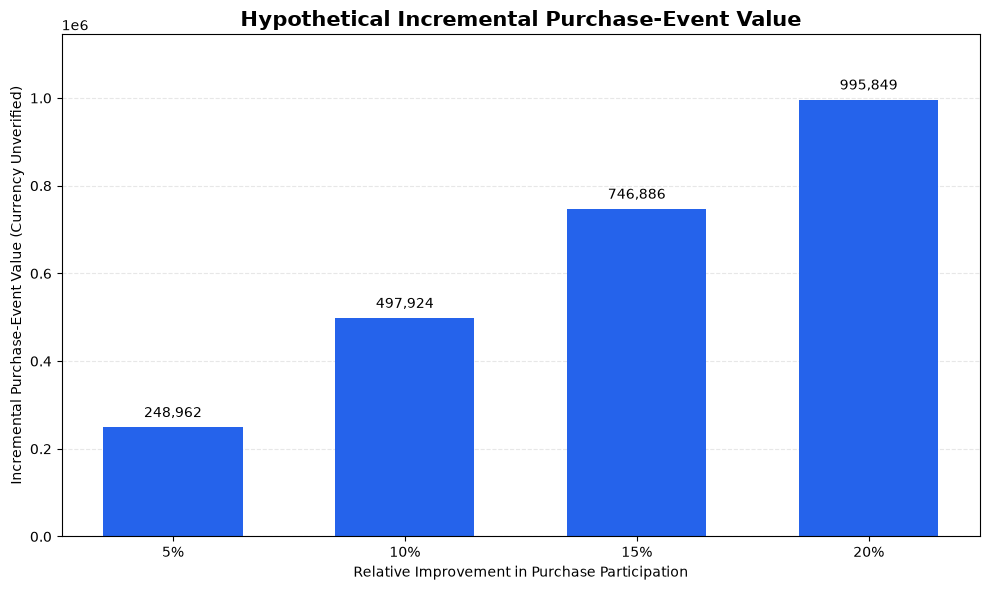

Visualization generated successfully.
Note: These are hypothetical scenarios, not forecasts.


In [16]:

# Step 07.23 — Purchase-Value Opportunity Visualization

import matplotlib.pyplot as plt

# 1. Prepare scenario data
scenario_labels = scenario_df[
    "relative_improvement"
]

incremental_values = scenario_df[
    "incremental_purchase_value"
]

# 2. Create visualization
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    scenario_labels,
    incremental_values,
    color="#2563EB",
    width=0.6
)

# 3. Add value labels
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

# 4. Chart formatting
ax.set_title(
    "Hypothetical Incremental Purchase-Event Value",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Relative Improvement in Purchase Participation")
ax.set_ylabel("Incremental Purchase-Event Value (Currency Unverified)")

ax.set_ylim(0, incremental_values.max() * 1.15)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("Visualization generated successfully.")
print("Note: These are hypothetical scenarios, not forecasts.")


In [17]:

# Step 07.24 — Purchase-Value Sensitivity Analysis

import pandas as pd

# 1. Define hypothetical value-per-purchaser adjustments
value_adjustments = [-0.20, -0.10, 0.00, 0.10, 0.20]

# 2. Calculate sensitivity scenarios
sensitivity_results = []

for improvement in improvement_scenarios:

    projected_rate = min(
        baseline_participation * (1 + improvement),
        1.0
    )

    additional_purchasers = (
        total_customers
        * (projected_rate - baseline_participation)
    )

    for adjustment in value_adjustments:

        adjusted_value_per_purchaser = (
            baseline_value_per_purchaser
            * (1 + adjustment)
        )

        incremental_value = (
            additional_purchasers
            * adjusted_value_per_purchaser
        )

        sensitivity_results.append({
            "participation_improvement": f"{improvement:.0%}",
            "value_per_purchaser_change": f"{adjustment:+.0%}",
            "incremental_purchase_value": round(
                incremental_value, 2
            )
        })

# 3. Create sensitivity table
sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_table = sensitivity_df.pivot(
    index="participation_improvement",
    columns="value_per_purchaser_change",
    values="incremental_purchase_value"
)

sensitivity_table = sensitivity_table.reindex(
    index=["5%", "10%", "15%", "20%"],
    columns=["-20%", "-10%", "+0%", "+10%", "+20%"]
)

print("=== PURCHASE-VALUE SENSITIVITY ANALYSIS ===")

display(
    sensitivity_table.style.format("{:,.2f}")
)

print("\nAll scenarios are hypothetical.")
print("Currency remains unverified.")
print("Incremental purchase value is not profit or ROI.")


=== PURCHASE-VALUE SENSITIVITY ANALYSIS ===


value_per_purchaser_change,-20%,-10%,+0%,+10%,+20%
participation_improvement,,,,,
5%,"199,169.70","224,065.92","248,962.13","273,858.34","298,754.56"
10%,"398,339.41","448,131.84","497,924.26","547,716.69","597,509.11"
15%,"597,509.11","672,197.75","746,886.39","821,575.03","896,263.67"
20%,"796,678.82","896,263.67","995,848.52","1,095,433.38","1,195,018.23"



All scenarios are hypothetical.
Currency remains unverified.
Incremental purchase value is not profit or ROI.


In [18]:

# Step 07.25 — Validate Sensitivity Analysis

import math

# 1. Verify table dimensions
assert sensitivity_table.shape == (4, 5)

# 2. Verify all 20 combinations
assert len(sensitivity_df) == 20

assert not sensitivity_table.isna().any().any()

# 3. Verify baseline scenarios
for _, row in scenario_df.iterrows():

    improvement = row["relative_improvement"]

    sensitivity_value = sensitivity_table.loc[
        improvement, "+0%"
    ]

    baseline_value = row["incremental_purchase_value"]

    assert math.isclose(
        sensitivity_value,
        baseline_value,
        abs_tol=0.01
    )

# 4. Verify sensitivity ordering
for improvement in sensitivity_table.index:

    values = sensitivity_table.loc[
        improvement
    ].tolist()

    assert all(
        values[i] <= values[i + 1]
        for i in range(len(values) - 1)
    )

# 5. Verify all modeled values are nonnegative
assert (
    sensitivity_df["incremental_purchase_value"] >= 0
).all()

print("=== SENSITIVITY ANALYSIS VALIDATION ===")
print("Table dimensions: PASSED")
print("20 scenario combinations: PASSED")
print("Missing values: PASSED")
print("Baseline reconciliation: PASSED")
print("Sensitivity ordering: PASSED")
print("Nonnegative values: PASSED")
print("\nALL SENSITIVITY CHECKS PASSED")


=== SENSITIVITY ANALYSIS VALIDATION ===
Table dimensions: PASSED
20 scenario combinations: PASSED
Missing values: PASSED
Baseline reconciliation: PASSED
Sensitivity ordering: PASSED
Nonnegative values: PASSED

ALL SENSITIVITY CHECKS PASSED


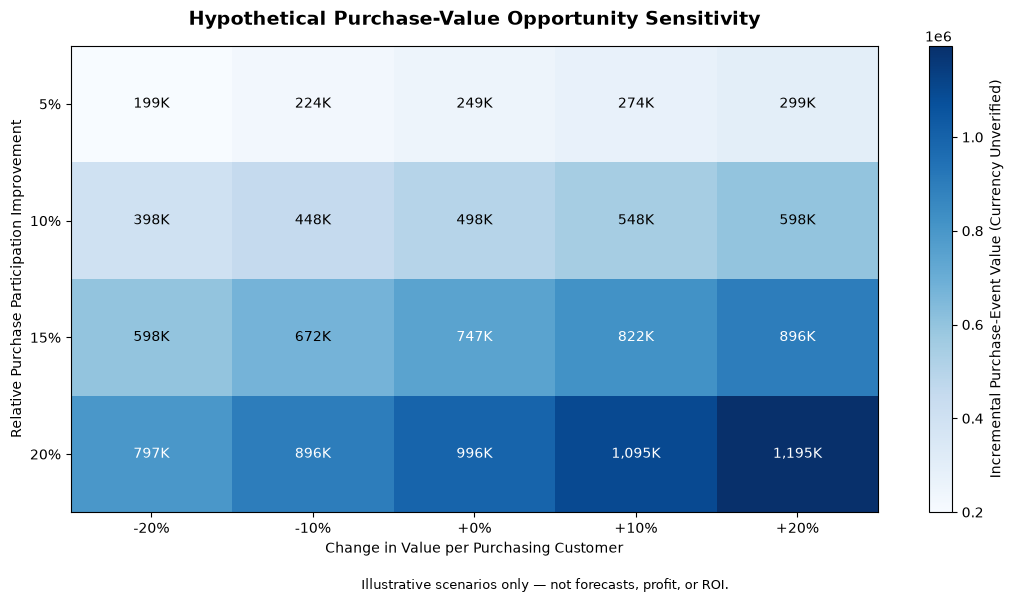

Sensitivity heatmap generated successfully.


In [19]:

# Step 07.26 — Sensitivity Analysis Heatmap

import matplotlib.pyplot as plt
import numpy as np

# 1. Prepare heatmap values
heatmap_values = sensitivity_table.to_numpy(dtype=float)

# 2. Create heatmap
fig, ax = plt.subplots(figsize=(11, 6))

heatmap = ax.imshow(
    heatmap_values,
    cmap="Blues",
    aspect="auto"
)

# 3. Add axis labels
ax.set_xticks(np.arange(len(sensitivity_table.columns)))
ax.set_yticks(np.arange(len(sensitivity_table.index)))

ax.set_xticklabels(sensitivity_table.columns)
ax.set_yticklabels(sensitivity_table.index)

ax.set_xlabel("Change in Value per Purchasing Customer")
ax.set_ylabel("Relative Purchase Participation Improvement")

ax.set_title(
    "Hypothetical Purchase-Value Opportunity Sensitivity",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# 4. Add values inside cells
threshold = (
    heatmap_values.min() + heatmap_values.max()
) / 2

for i in range(heatmap_values.shape[0]):
    for j in range(heatmap_values.shape[1]):
        value = heatmap_values[i, j]

        ax.text(
            j,
            i,
            f"{value / 1000:,.0f}K",
            ha="center",
            va="center",
            color="white" if value > threshold else "black",
            fontsize=10
        )

# 5. Add colorbar
colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label(
    "Incremental Purchase-Event Value (Currency Unverified)"
)

fig.text(
    0.5,
    0.01,
    "Illustrative scenarios only — not forecasts, profit, or ROI.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

print("Sensitivity heatmap generated successfully.")



# Step 07.27 — Business Recommendations

## 1. Executive Summary

The October customer sample contains:

- 60,939 unique customers.
- 7,099 purchasing customers.
- 11.65% customer purchase participation.
- 15,435 purchase events.
- 4,979,242.62 in recorded purchase-event value.

The recorded purchase-event value is a revenue proxy,
not verified business revenue.

Currency remains unverified.

## 2. Key Business Findings

### Finding 1 — Customer Activity Matters

Purchase participation increases across activity segments:

- Low Activity: 2.15%
- Medium Activity: 12.57%
- High Activity: 25.47%
- Very High Activity: 48.62%

This is an observed association, not proof of causation.

### Finding 2 — Purchase Value Is Concentrated

The top 10% of purchasing customers contribute
60.20% of recorded purchase-event value.

This suggests that understanding high-value customer
behavior is an important analytical priority.

### Finding 3 — Category Concentration

The electronics.smartphone category contributes
70.03% of recorded purchase-event value.

Category concentration should be considered when
evaluating business risks and growth opportunities.

## 3. Recommended Business Actions

### Recommendation 1 — Improve Product Discovery

Investigate barriers affecting low-activity customers.

Potential experiments:

- Improve product search.
- Improve product recommendations.
- Simplify product navigation.

### Recommendation 2 — Optimize the View-to-Cart Funnel

Prioritize investigation of view-to-cart friction
using the validated journey-level funnel.

Potential experiments:

- Improve product detail pages.
- Clarify product information.
- Improve add-to-cart visibility.

### Recommendation 3 — Understand High-Value Customers

Analyze purchasing frequency, product preferences,
and repeat purchase behavior.

Avoid assuming that high-value customers are
necessarily more profitable.

### Recommendation 4 — Evaluate Category Concentration

Investigate dependence on smartphone purchase value.

Explore opportunities in other product categories
without assuming that diversification guarantees growth.

## 4. Hypothetical Financial Opportunity

Modeled relative improvements in customer purchase
participation produce the following incremental
purchase-event values:

- 5% improvement: 248,962.13
- 10% improvement: 497,924.26
- 15% improvement: 746,886.39
- 20% improvement: 995,848.52

These are illustrative scenarios, not forecasts.

They assume that incremental purchasing customers
generate the historical average purchase-event value
per purchasing customer.

They do not represent profit, ROI, or verified revenue.

## 5. Recommended Next Steps

1. Investigate view-to-cart friction.
2. Prioritize testable product-discovery hypotheses.
3. Design controlled A/B experiments.
4. Monitor journey-level conversion and guardrail metrics.
5. Validate improvements before estimating business impact.

## 6. Analytical Limitations

- Analysis uses the cleaned October customer sample.
- Currency is unverified.
- Purchase events are not necessarily unique orders.
- Recorded purchase-event value is a revenue proxy.
- Observational relationships do not establish causation.
- Financial scenarios are hypothetical.
- Gross purchase-value uplift is not profit or ROI.


In [23]:

# Step 07.28 — Final Revenue Model Validation

print("========== PHASE 07 FINAL VALIDATION ==========")

# 1. Dataset baseline
assert len(df) == 849220
assert total_customers == 60939
assert purchasing_customers == 7099

print("Dataset and customer counts: PASSED")

# 2. Purchase-event baseline
assert purchase_event_count == 15435
assert abs(float(total_purchase_value) - 4979242.62) < 0.01
assert missing_prices == 0
assert invalid_prices == 0

print("Purchase-event baseline: PASSED")

# 3. Customer participation
assert abs(
    (purchasing_customers / total_customers * 100)
    - 11.65
) < 0.01

print("Customer purchase participation: PASSED")

# 4. Activity segment reconciliation
assert activity_value_summary["customers"].sum() == total_customers

assert (
    activity_value_summary["purchasing_customers"].sum()
    == purchasing_customers
)

assert abs(
    activity_value_summary["purchase_value"].sum()
    - float(total_purchase_value)
) < 0.01

print("Activity segment reconciliation: PASSED")

# 5. Opportunity scenarios
assert len(scenario_df) == 4
assert scenario_df["incremental_purchase_value"].is_monotonic_increasing

print("Opportunity scenario validation: PASSED")

# 6. Sensitivity analysis

# 6. Sensitivity analysis
assert sensitivity_df.shape == (20, 3)

assert sensitivity_df.notna().all().all()

assert sensitivity_df["participation_improvement"].nunique() == 4

assert sensitivity_df["value_per_purchaser_change"].nunique() == 5

assert not sensitivity_df.duplicated(
    subset=[
        "participation_improvement",
        "value_per_purchaser_change"
    ]
).any()

print("Sensitivity analysis validation: PASSED")


print("Sensitivity analysis validation: PASSED")

print("\n========== ALL PHASE 07 CHECKS PASSED ==========")


========== PHASE 07 FINAL VALIDATION ==========
Dataset and customer counts: PASSED
Purchase-event baseline: PASSED
Customer purchase participation: PASSED
Activity segment reconciliation: PASSED
Opportunity scenario validation: PASSED
Sensitivity analysis validation: PASSED
Sensitivity analysis validation: PASSED

========== ALL PHASE 07 CHECKS PASSED ==========


In [22]:

# Step 07.28A — Inspect Sensitivity DataFrame

print("=== SENSITIVITY DATAFRAME DIAGNOSTICS ===")

print("Shape:", sensitivity_df.shape)
print("Columns:", sensitivity_df.columns.tolist())
print("Index:", sensitivity_df.index.tolist())

print("\nFirst five rows:")
display(sensitivity_df.head())

print("\nMissing values:")
print(sensitivity_df.isna().sum())


=== SENSITIVITY DATAFRAME DIAGNOSTICS ===
Shape: (20, 3)
Columns: ['participation_improvement', 'value_per_purchaser_change', 'incremental_purchase_value']
Index: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

First five rows:


,participation_improvement,value_per_purchaser_change,incremental_purchase_value
0,5%,-20%,199169.70
1,5%,-10%,224065.92
2,5%,+0%,248962.13
3,5%,+10%,273858.34
4,5%,+20%,298754.56



Missing values:
participation_improvement     0
value_per_purchaser_change    0
incremental_purchase_value    0
dtype: int64
